# Praktikum 6 - Pencarian Track pada Micro Spotify

**Nama:** Agus

**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-ann-approximate-nearest-neighbors/praktikum-6)

## Langkah 0 - Persiapan Lingkungan

In [1]:
import sys
import numpy as np
np.random.seed(42)
print("Kernel:", sys.executable)

import faiss
faiss.omp_set_num_threads(4)


Kernel: /Volumes/External/miniconda3/envs/ml-praktikum/bin/python


## Data dan Penyesuaian Kode

Dataset berasal dari file pertama `songs_with_attributes_and_lyrics.csv` pada sumber Kaggle modul. `data/spotify_songs.csv.gz` mempertahankan seluruh baris dan sembilan fitur numerik yang dipakai kode modul; kolom lirik tidak diperlukan. Provenance dicatat di data/README.md. Path Google Drive diganti dengan path lokal.

Pada FAISS terpasang, constructor dengan keyword `nlist` menghasilkan TypeError. Hanya pemanggilan constructor itu diganti menjadi argumen posisi. Kode pencarian tetap memakai seluruh baris sebagai database dan query.

## Langkah 1 - Import Library

In [2]:
import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Load dataset
# -------------------------------
df = pd.read_csv('data/spotify_songs.csv.gz')  # ganti path sesuai lokasi file
features = ['danceability', 'energy', 'loudness', 'speechiness', 
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
X = df[features].values

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact Nearest Neighbor (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=X_scaled.shape[1])
p_hnsw.init_index(max_elements=X_scaled.shape[0], ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, dist_hnsw = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(X_scaled.shape[1])
index_faiss = faiss.IndexIVFFlat(quantizer, X_scaled.shape[1], 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
dist_faiss, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Contoh tampilkan top-5 neighbors dari item pertama
# -------------------------------
print("\nTop-5 neighbors for first song:")
print(f"Exact NN: {idx_exact[0][:5]}")
print(f"Annoy:    {idx_annoy[0][:5]}")
print(f"HNSW:     {idx_hnsw[0][:5]}")
print(f"FAISS:    {idx_faiss[0][:5]}")


Exact NN done in 659.619 s


Annoy done in 19.779 s


HNSW done in 31.478 s


FAISS IVF done in 156.541 s

Top-5 neighbors for first song:
Exact NN: [     0 394553 764272 837727 749223]
Annoy:    [0, 394553, 764272, 837727, 61511]
HNSW:     [     0 394553 764272 837727 749223]
FAISS:    [     0 394553 764272 837727 749223]


## Ringkasan Hasil

,Model,Total build + query (s),Recall@10
0,Exact NN,659.6189,1.0000
1,Annoy,19.7785,0.8353
2,HNSW,31.4782,0.9945
3,FAISS IVF,156.5408,0.9977


Jumlah baris database dan query: 955320
Jumlah fitur: 9
Semua baris dicari terhadap database yang sama, termasuk item itu sendiri.


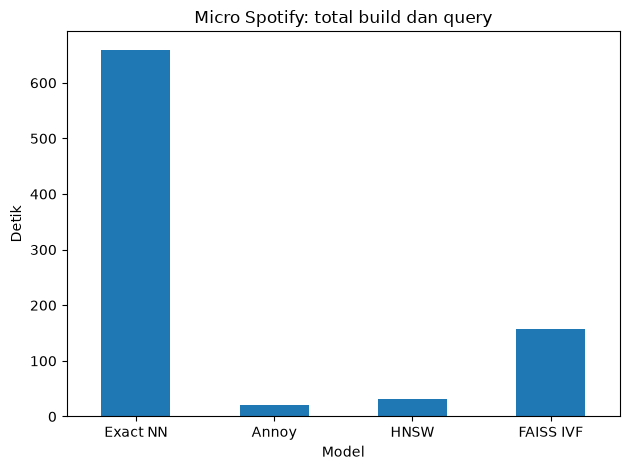

In [3]:
import matplotlib.pyplot as plt
from IPython.display import display

def recall_spotify(pred, truth):
    return sum(len(set(a) & set(b)) for a, b in zip(pred, truth)) / (len(truth) * k)

spotify_comparison = pd.DataFrame([
    {'Model': 'Exact NN', 'Total build + query (s)': time_exact, 'Recall@10': 1.0},
    {'Model': 'Annoy', 'Total build + query (s)': time_annoy, 'Recall@10': recall_spotify(idx_annoy, idx_exact)},
    {'Model': 'HNSW', 'Total build + query (s)': time_hnsw, 'Recall@10': recall_spotify(idx_hnsw, idx_exact)},
    {'Model': 'FAISS IVF', 'Total build + query (s)': time_faiss, 'Recall@10': recall_spotify(idx_faiss, idx_exact)},
])
display(spotify_comparison.round(4))
print('Jumlah baris database dan query:', len(X_scaled))
print('Jumlah fitur:', X_scaled.shape[1])
print('Semua baris dicari terhadap database yang sama, termasuk item itu sendiri.')
spotify_comparison.plot.bar(x='Model', y='Total build + query (s)', legend=False,
                            title='Micro Spotify: total build dan query', ylabel='Detik', rot=0)
plt.tight_layout()
plt.show()


## Analisis

StandardScaler menyetarakan skala fitur: tempo dan loudness tidak mendominasi hanya karena satuannya lebih besar. Semua model menerima sembilan fitur dan database yang sama. Waktu modul mencakup build serta query seluruh track, sehingga berbeda dari latency satu query pada praktikum sebelumnya. ANN dapat melewatkan tetangga exact; recall diperlukan untuk menilai hasilnya. Item pertama juga menjadi kandidat tetangganya sendiri, sehingga daftar ini belum langsung menjadi rekomendasi lagu lain. Baris dengan fitur identik dapat menghasilkan ID berbeda pada jarak seri. Kemiripan fitur audio tidak otomatis menunjukkan selera pendengar karena tidak ada riwayat pengguna.